# Multi Layer Perceptron Approach by Bengio et al. 2003

In [1]:
# Mostly focused around Train Test Split

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [3]:
words = open('names.txt').read().splitlines()

In [4]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [5]:
len(words)

32033

In [6]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


**Note:** we are not doing ```.emma.```  and then doing indexing. But instead we are just doing ```emma.```. This is beacuase the `.` at the beginning is being handled by the padded context of `[0,0,0]` that we start with.

The thing gets handled automatically without us having to set is manually

In [7]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predit the next character.
X, Y = [], []

for w in words:

    #print(w)
    context = [0]* block_size

    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix] # Crop and append, this is the main thing being done here. we shift exisitng characters left by 1 and add the newest cahracter to the right. The left most character gets cut off

X = torch.tensor(X)
Y = torch.tensor(Y)

In [8]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)


## 13. Why a Lower Training Loss Doesn't Necessarily Mean a Better Model

- We currently have a neural network with approximately 3,400 parameters.
- Our loss is around **2.3**, which is lower than the bigram model's loss of approximately **2.45**.
- It might seem that we have built a better model. However, that's not necessarily true.

### The Problem: Overfitting

Our current model is relatively small, but neural networks can become much larger as we keep adding neurons and parameters.

For example, instead of having 3,400 parameters, we could have:
- 10,000 parameters.
- 100,000 parameters.
- Millions of parameters.

As the capacity of a neural network grows, it becomes increasingly capable of **overfitting the training set**.

What happens during overfitting?

- The loss on the training data can become extremely low, potentially even zero.
- However, the model might simply be memorizing the training examples verbatim rather than learning meaningful patterns.

This creates two problems:

1. **Poor generation:** If we try to sample from the model, we might only get examples that already exist in the training dataset. We won't get genuinely new examples.
2. **Poor generalization:** If we evaluate the model on withheld names or other examples that it hasn't seen during training, the loss can be very high.

Therefore, a model with a very low training loss is not necessarily a good model.

## 14. Splitting the Dataset: Train, Validation and Test

The standard practice in machine learning is to divide the dataset into three separate splits:

1. Training set
2. Development (Dev) / Validation set
3. Test set

A typical split might look like this:

| Dataset Split | Percentage | Purpose |
|---|---:|---|
| Training | 80% | Optimize model parameters |
| Validation / Dev | 10% | Tune hyperparameters |
| Test | 10% | Evaluate final model performance |

### 1. Training Set (80%)

- The training set is used to optimize the parameters of the neural network.
- We use gradient descent and backpropagation to update the model parameters.
- This is what we have been doing so far.

### 2. Validation / Dev Set (10%)

- The validation set is used during model development to experiment with different hyperparameters and determine which configuration works best.
- Hyperparameters are design choices that define the neural network.

Examples of hyperparameters include:

- **Hidden layer size:** We currently have 100 neurons, but we could experiment with different sizes.
- **Embedding dimension:** We currently use an embedding dimension of 2, but we could try different dimensions.
- **Regularization strength:** We haven't introduced regularization yet, but this is another hyperparameter we can experiment with.

We can try different combinations of these hyperparameters and evaluate their performance on the validation set.

The configuration that performs best on the validation set is generally preferred.

**Important distinction:**

- Training data is used to optimize the model parameters.
- Validation data is used to tune the hyperparameters.

### 3. Test Set (10%)

- The test set is used to evaluate the final performance of the model.
- We should evaluate the loss on the test set very sparingly, ideally only after we have finalized our model.

**Why should we evaluate on the test set only a few times?**

Every time we evaluate the test loss and learn something from it, we might start making decisions based on the test results.

Eventually, we risk indirectly optimizing our model for the test set as well.

This means we are effectively overfitting the test set through repeated experimentation.

Therefore, the test set should remain untouched during model development and should only be used for final evaluation.

## 15. Implementing the Train, Validation and Test Splits

Now we need to modify our dataset creation process to generate three separate datasets.

### Step 1: Create a Dataset-Building Function

Previously, we directly converted all the words into `X` and `Y` tensors.

Now, we create a function that takes a list of words and builds the corresponding input and target arrays.

Conceptually:

```python
def build_dataset(words):
    # Build X and Y using only the supplied words
    ...
    return X, Y
```

This allows us to independently construct the training, validation and test datasets.

### Step 2: Shuffle the Words

Before splitting the dataset, we randomly shuffle all the words.

This ensures that the three splits contain randomly distributed examples rather than potentially biased groups of words.

### Step 3: Determine the Split Boundaries

Suppose we have approximately 30,000 words.

We define:

```python
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
```

This gives us approximately:

- `n1 = 25,000`
- `n2 = 28,000`

### Step 4: Build the Three Datasets

We now call `build_dataset()` separately for each split.

```python
Xtr, Ytr = build_dataset(words[:n1])

Xdev, Ydev = build_dataset(words[n1:n2])

Xte, Yte = build_dataset(words[n2:])
```

The resulting datasets contain approximately:

| Dataset | Number of Words |
|---|---:|
| Training | 25,000 |
| Validation / Dev | 3,000 |
| Test | 3,204 |
| Total | 31,204 |

Each dataset has its own input (`X`) and target (`Y`) tensors.

**Important:** We now have three separate datasets, and we will use them for different purposes:

- Train the neural network using the training split.
- Evaluate different hyperparameter configurations using the validation split.
- Evaluate the final model using the test split, very sparingly.


In [10]:
# build the dataset

def build_dataset(words):
    block_size = 3 # context length: how many characters do we take to predict the next one?
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]    # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

In [11]:
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [12]:
# first pass of the neural net with Train Test split, but with same size as previous.

In [13]:
Xtr.shape, Ytr.shape    # dataset

(torch.Size([182625, 3]), torch.Size([182625]))

In [14]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [15]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [18]:
for i in range(10000):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Ytr[ix])
    #if i%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # # track stats
    # lri.append(lre[i])  # This is the part that changed from the above loop
    # lossi.append(loss.item())

In [19]:
print(loss.item())

2.1721768379211426


In [ ]:
# Train with lr = 0.1 till it reaches a good enough point. Then train with 0.01 to see if loss can be further decreased

In [20]:
# check loss on the Complete Training dataset
emb = C[Xtr] # [m, 3, 2]
h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ytr)
loss

tensor(2.5110, grad_fn=<NllLossBackward0>)

In [21]:
# check loss on the dev dataset
emb = C[Xdev] # [m, 3, 2]
h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ydev)
loss

tensor(2.5043, grad_fn=<NllLossBackward0>)

In [ ]:
# When the trainiing loss and the dev loss are roughly equal, this means we are underfitting.
# We can expect to have performance imporvements by scaling up the size of the Neural Net

In [ ]:
# ------------Increase the size of the Neural Net -------------

In [29]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 300), generator=g)
b1 = torch.randn(300, generator=g)
W2 = torch.randn((300, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [30]:
sum(p.nelement() for p in parameters) # number of parameters in total

10281

In [46]:
lri = []
lossi = []
stepi = []

for i in range(30000):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Ytr[ix])
    #if i%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    #lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.item())

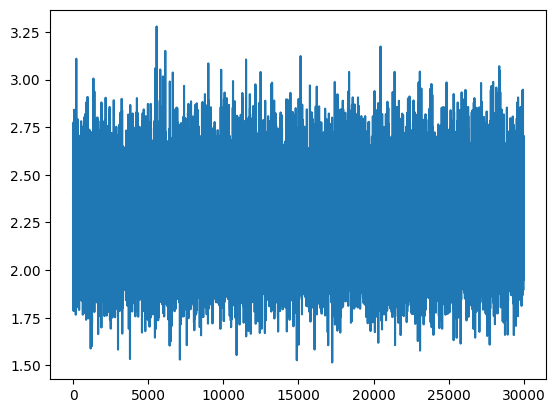

In [47]:
plt.plot(stepi, lossi)

In [48]:
# check loss on the Complete Training dataset
emb = C[Xtr] # [m, 3, 2]
h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ytr)
loss

tensor(2.2570, grad_fn=<NllLossBackward0>)

In [49]:
# check loss on the dev dataset
emb = C[Xdev] # [m, 3, 2]
h = torch.tanh(emb.view(-1,6) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ydev)
loss

tensor(2.2624, grad_fn=<NllLossBackward0>)

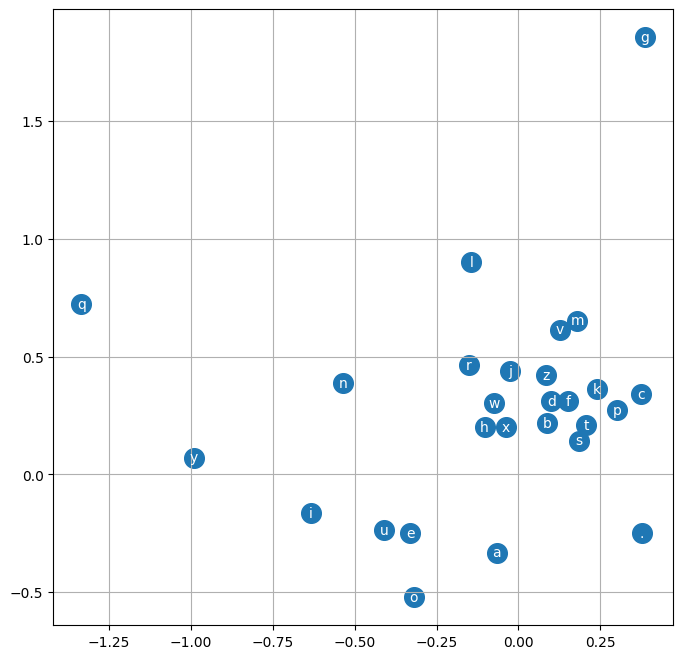

In [50]:
 # visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [51]:
# By just increasing the size of the neural net, we were not able to reducr the loss further, we think the issue might be with embedding_dim. So we'll now increase the embedding dim from 2 to 10

In [52]:
# ------------Increase the emdedding dim to 10 -------------

In [57]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True

In [58]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [59]:
lri = []
lossi = []
stepi = []

In [69]:
for i in range(50000):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # [32, 3, 2]
    h = torch.tanh(emb.view(-1,30) @ W1 + b1)    # [32, 100]
    logits = h @ W2 + b2                        #[32, 27]
    loss = F.cross_entropy(logits,Ytr[ix])
    #if i%10 ==0: print(loss.item())

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.01
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    #lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

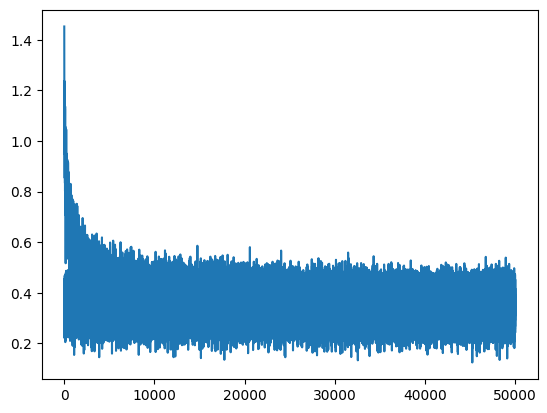

In [70]:
plt.plot(stepi, lossi)

In [71]:
# The stick bottom is very thick because the mini-batch size is very small.

In [72]:
# check loss on the Complete Training dataset
emb = C[Xtr] # [m, 3, 2]
h = torch.tanh(emb.view(-1,30) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ytr)
loss

tensor(2.1200, grad_fn=<NllLossBackward0>)

In [73]:
# check loss on the dev dataset
emb = C[Xdev] # [m, 3, 2]
h = torch.tanh(emb.view(-1,30) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ydev)
loss

tensor(2.1627, grad_fn=<NllLossBackward0>)

In [ ]:
 # What can be changed form here
 # 1. Embedding size
 # 2. Change the size of the Neural Net (hidden layer size)
 # 3. Take more characters than 3 as context window
 # 4. Learning Rate, Decay of Learning Rate
 # 5. No of iterations to run the training loop.
 # 6. Batch size for mini batch GD.

In [74]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

carmah.
amilli.
khi.
mili.
taty.
hachysne.
mahnee.
delyah.
jareei.
ner.
kiah.
maiiv.
kaleigh.
ham.
jory.
quinn.
sulin.
alian.
quinathousearyni.
jace.


In [77]:
# Bigger Training Loop

In [78]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
  p.requires_grad = True


In [76]:
sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [79]:
lri = []
lossi = []
stepi = []

In [80]:
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, 3, 10)
  h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 200)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

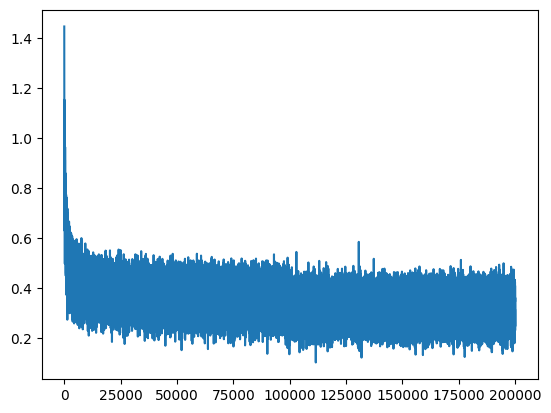

In [81]:
plt.plot(stepi, lossi)

In [82]:
# check loss on the Complete Training dataset
emb = C[Xtr] # [m, 3, 2]
h = torch.tanh(emb.view(-1,30) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ytr)
loss

tensor(2.1229, grad_fn=<NllLossBackward0>)

In [83]:
# check loss on the dev dataset
emb = C[Xdev] # [m, 3, 2]
h = torch.tanh(emb.view(-1,30) @ W1 + b1)    # [m, 100]
logits = h @ W2 + b2                        #[m, 27]
loss = F.cross_entropy(logits,Ydev)
loss

tensor(2.1531, grad_fn=<NllLossBackward0>)

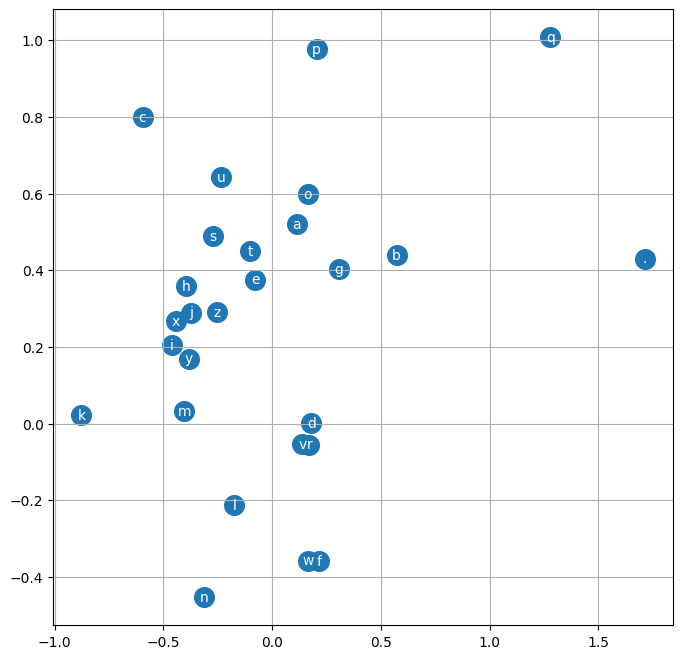

In [84]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [85]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [86]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))


carlah.
amelle.
khiemri.
reviyah.
cassie.
mahnen.
dellynn.
kaeli.
nermari.
chaiir.
kaleigh.
ham.
joir.
quint.
sulin.
alianni.
wanthoudearynix.
kaellinsley.
dae.
oiy.
